# 06 · Previsão de demanda e receita

**Pergunta:** se nada mudar, quanto a operação deve vender até o fim de 2018, incluindo a Black Friday?

**Série usada:** pedidos válidos por dia, de mar/2017 (quando o fluxo diário se regulariza) a 21/08/2018 (último dia antes do corte da extração).

**Eventos de calendário e externos** considerados:
- **Black Friday** (24/11/2017 e 23/11/2018) e os 4 dias seguintes;
- **festas de fim de ano** (22/12 a 01/01);
- **greve dos caminhoneiros** (21/05 a 03/06/2018), que paralisou a logística do país e derrubou as vendas pela metade. É tratada como evento passado e não se repete na projeção.

**Métodos comparados:**
1. **Média simples:** repete o ritmo diário dos últimos 28 dias;
2. **SARIMA:** modelo estatístico de séries temporais com sazonalidade semanal e os eventos acima;
3. **Ritmo recente + calendário:** o ritmo dos últimos 28 dias, já descontados os eventos, multiplicado pelos efeitos de calendário que o SARIMA estima (por exemplo, quantas vezes a Black Friday vende mais que um dia comum).

## Principais conclusões

- **Métodos simples venceram o modelo complexo:** na validação com dados de 2018, a média simples e o ritmo + calendário erram de 8% a 14% no total do mês; o SARIMA puro, de 12% a 27%. Adotamos o ritmo + calendário por ser o único que captura a Black Friday e as festas.
- **Efeitos de calendário:** o dia da Black Friday vende 4,2 vezes um dia comum, e os 4 dias seguintes, 1,8 vez. As festas de fim de ano vendem cerca de metade, e a greve de 2018 derrubou as vendas em 22%.
- **Projeção central:** 7,8 mil pedidos em set/2018, 8,3 mil em out, 9,5 mil em nov (contra 7,4 mil em nov/2017) e 6,9 mil em dez.
- **2018 deve fechar com cerca de 88 mil pedidos e R$ 14,3 milhões em receita**, o dobro de 2017 (+101%), numa faixa de R$ 13,0 a 15,5 milhões.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

In [2]:
pedidos = prep.carregar_base_pedidos()
validos = pedidos[pedidos.valido]
serie = validos.set_index("order_purchase_timestamp").resample("D").size()
serie = serie.loc["2017-03-01":config.FIM_SERIE_DIARIA].asfreq("D", fill_value=0)

BLACK_FRIDAYS = [pd.Timestamp("2017-11-24"), pd.Timestamp("2018-11-23")]

def exogenas(indice):
    x = pd.DataFrame(0.0, index=indice, columns=["black_friday", "pos_black_friday", "festas", "greve"])
    for bf in BLACK_FRIDAYS:
        x.loc[x.index == bf, "black_friday"] = 1
        x.loc[(x.index > bf) & (x.index <= bf + pd.Timedelta(days=4)), "pos_black_friday"] = 1
    x.loc[((x.index.month == 12) & (x.index.day >= 22)) | ((x.index.month == 1) & (x.index.day == 1)), "festas"] = 1
    x.loc["2018-05-21":"2018-06-03", "greve"] = 1
    return x

def ajustar(y):
    """SARIMA em log com os eventos presentes no período de treino."""
    x = exogenas(y.index)
    colunas = [c for c in x if x[c].any()]
    ajuste = SARIMAX(np.log1p(y), exog=x[colunas], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7)).fit(disp=False)
    efeitos = {c: np.exp(ajuste.params[c]) for c in colunas}
    return ajuste, colunas, efeitos

def multiplicador(x, efeitos):
    m = np.ones(len(x))
    for coluna, efeito in efeitos.items():
        m = m * np.where(x[coluna].values == 1, efeito, 1.0)
    return pd.Series(m, index=x.index)

def exogenas_futuras(dias, colunas):
    x = exogenas(dias)[colunas].copy()
    if "greve" in colunas:
        x["greve"] = 0  # evento imprevisível: não entra na projeção
    return x

print(f"{len(serie)} dias, de {serie.index.min():%d/%m/%Y} a {serie.index.max():%d/%m/%Y}")

539 dias, de 01/03/2017 a 21/08/2018


## 1. Validação: qual método teria acertado mais em 2018?

Simulamos a previsão como ela teria sido feita no 1º dia de cada mês de 2018, usando só os dados disponíveis até ali, e medimos o erro no total de pedidos do mês seguinte (horizonte 1), do outro (horizonte 2) e do terceiro (horizonte 3).

In [3]:
linhas = []
for origem in pd.date_range("2018-01-01", "2018-08-01", freq="MS"):
    treino = serie.loc[:origem - pd.Timedelta(days=1)]
    ajuste, colunas, efeitos = ajustar(treino)
    ritmo_base = (treino / multiplicador(exogenas(treino.index)[colunas], efeitos)).iloc[-28:].mean()
    for h in (1, 2, 3):
        inicio_alvo = origem + pd.DateOffset(months=h - 1)
        if inicio_alvo > serie.index[-1]:
            continue
        fim_alvo = min(inicio_alvo + pd.offsets.MonthEnd(0), serie.index[-1])
        dias = pd.date_range(origem, fim_alvo, freq="D")
        x_fut = exogenas_futuras(dias, colunas)
        sarima = pd.Series(np.expm1(np.asarray(ajuste.get_forecast(len(dias), exog=x_fut).predicted_mean)), index=dias)
        ritmo = ritmo_base * multiplicador(x_fut, efeitos)
        linhas.append({
            "origem": origem, "horizonte": h, "real": serie.loc[inicio_alvo:fim_alvo].sum(),
            "Média simples": treino.iloc[-28:].mean() * len(pd.date_range(inicio_alvo, fim_alvo)),
            "SARIMA": sarima.loc[inicio_alvo:fim_alvo].sum(),
            "Ritmo recente + calendário": ritmo.loc[inicio_alvo:fim_alvo].sum(),
        })
validacao = pd.DataFrame(linhas)
metodos = ["Média simples", "SARIMA", "Ritmo recente + calendário"]
erros = validacao[metodos].sub(validacao.real, axis=0).abs().div(validacao.real, axis=0)
mape = erros.groupby(validacao.horizonte).mean()
mape.index = [f"{h} {'mês' if h == 1 else 'meses'} à frente" for h in mape.index]
mape.map(pct)

,Média simples,SARIMA,Ritmo recente + calendário
1 mês à frente,"8,3%","11,8%","10,0%"
2 meses à frente,"11,2%","22,4%","12,8%"
3 meses à frente,"13,9%","26,5%","10,1%"


In [4]:
detalhe = validacao[validacao.horizonte == 1].set_index("origem")[["real"] + metodos].round(0).astype(int)
detalhe.index = [viz.mes_ano(m) + (" (até dia 21)" if m.month == 8 else "") for m in detalhe.index]
detalhe

,real,Média simples,SARIMA,Ritmo recente + calendário
jan/18,7187,5424,5111,5934
fev/18,6624,6690,6549,6690
mar/18,7168,7334,8517,7334
abr/18,6919,6881,6573,6881
mai/18,6833,7121,7449,7121
jun/18,6145,6407,7469,7620
jul/18,6233,6442,6315,6516
ago/18 (até dia 21),5738,4248,5244,4248


**Leitura.** O SARIMA puro reage demais às últimas semanas e erra mais à medida que o horizonte cresce. A média simples e o ritmo + calendário ficam próximos, com erro de cerca de 10% a 14%. O ritmo + calendário erra mais em jun/2018 porque a recuperação pós-greve foi lenta e coincidiu com a Copa do Mundo. Em compensação, acerta melhor janeiro (efeito das festas) e é o **único que captura a Black Friday**, decisiva para novembro. Por isso ele é o método da projeção.

## 2. Efeitos de calendário estimados

In [5]:
ajuste, colunas, efeitos = ajustar(serie)
nomes_efeitos = {"black_friday": "Dia da Black Friday", "pos_black_friday": "4 dias seguintes", "festas": "Festas (22/12 a 01/01)",
                 "greve": "Greve dos caminhoneiros"}
pd.Series({nomes_efeitos[c]: f"{e:.2f}x".replace(".", ",") for c, e in efeitos.items()}).to_frame("vendas vs. dia comum")

,vendas vs. dia comum
Dia da Black Friday,"4,18x"
4 dias seguintes,"1,80x"
Festas (22/12 a 01/01),"0,53x"
Greve dos caminhoneiros,"0,78x"


## 3. Projeção até dez/2018

**Faixa de incerteza.** Usamos os erros da validação: para cada horizonte, o erro médio observado (tornado crescente com o horizonte e extrapolado para 4 meses) é convertido numa faixa de 80% supondo erros normais (±1,6 × erro médio).

In [6]:
dias_futuros = pd.date_range(serie.index[-1] + pd.Timedelta(days=1), "2018-12-31", freq="D")
ritmo_atual = (serie / multiplicador(exogenas(serie.index)[colunas], efeitos)).iloc[-28:].mean()

# Padrão semanal (só para o gráfico diário; não muda os totais mensais)
recente = serie.loc["2018-01-01":]
fator_semana = (recente / recente.rolling(7, center=True).mean()).groupby(recente.index.dayofweek).mean()
fator_semana = fator_semana / fator_semana.mean()

diario_previsto = ritmo_atual * multiplicador(exogenas_futuras(dias_futuros, colunas), efeitos) * fator_semana.reindex(dias_futuros.dayofweek).values
projetado = diario_previsto.resample("MS").sum()
# Agosto soma o realizado até dia 21 (sem incerteza) e o projetado no restante do mês
realizado = pd.Series(0.0, index=projetado.index)
realizado.loc["2018-08-01"] = serie.loc["2018-08-01":].sum()

erro_ritmo = erros.groupby(validacao.horizonte)["Ritmo recente + calendário"].mean().cummax()
erro_horizonte = {1: erro_ritmo[1], 2: erro_ritmo[2], 3: erro_ritmo[3], 4: erro_ritmo[3] * np.sqrt(4 / 3)}
horizonte_mes = {8: 1, 9: 1, 10: 2, 11: 3, 12: 4}
erro_mes = pd.Series([erro_horizonte[horizonte_mes[m.month]] for m in projetado.index], index=projetado.index)
projecao = pd.DataFrame({
    "p10": realizado + projetado * (1 - 1.6 * erro_mes),
    "central": realizado + projetado,
    "p90": realizado + projetado * (1 + 1.6 * erro_mes),
})
projecao.index = [viz.mes_ano(m) for m in projecao.index]
print(f"Ritmo atual (descontados os eventos): {num(ritmo_atual)} pedidos/dia")
projecao.round(0).astype(int).assign(faixa_sobre_o_projetado=[f"±{pct(1.6 * e, 0)}" for e in erro_mes])

Ritmo atual (descontados os eventos): 264 pedidos/dia


,p10,central,p90,faixa_sobre_o_projetado
ago/18,7982,8410,8837,±16%
set/18,6566,7817,9068,±16%
out/18,6592,8294,9995,±21%
nov/18,7571,9526,11480,±21%
dez/18,5274,6912,8550,±24%


In [7]:
completos = validos[prep.no_periodo(validos.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_MES_COMPLETO)]
mensal_real = completos.groupby("mes").agg(pedidos=("order_id", "size"), gmv=("gmv", "sum"))
ticket = mensal_real.loc["2018-02-01":, "gmv"].sum() / mensal_real.loc["2018-02-01":, "pedidos"].sum()

real_2017 = mensal_real.loc["2017"].sum()
real_2018 = mensal_real.loc["2018"].sum()
cenarios = {nome: (real_2018.pedidos + projecao[nome].sum(), real_2018.gmv + projecao[nome].sum() * ticket)
            for nome in ["p10", "central", "p90"]}
crescimento_2018 = cenarios["central"][1] / real_2017.gmv - 1

print(f"Ticket médio usado: {brl(ticket)} (fev–jul/2018)")
print(f"Novembro/2018 projetado: {num(projecao.loc['nov/18', 'central'])} pedidos (nov/2017: {num(mensal_real.loc['2017-11-01', 'pedidos'])})")
print(f"Receita 2018 projetada vs 2017 (central): {pct(crescimento_2018)}")
pd.DataFrame({
    "pedidos": [num(real_2017.pedidos)] + [num(cenarios[c][0]) for c in cenarios],
    "receita": [brl(real_2017.gmv)] + [brl(cenarios[c][1]) for c in cenarios],
    "vs. 2017": ["—"] + [pct(cenarios[c][1] / real_2017.gmv - 1) for c in cenarios],
}, index=["2017 (realizado)", "2018: cenário baixo (p10)", "2018: central", "2018: cenário alto (p90)"])

Ticket médio usado: R$ 163 (fev–jul/2018)
Novembro/2018 projetado: 9.526 pedidos (nov/2017: 7.421)
Receita 2018 projetada vs 2017 (central): 101,1%


,pedidos,receita,vs. 2017
2017 (realizado),44.375,"R$ 7,1 mi",—
2018: cenário baixo (p10),81.095,"R$ 13,1 mi","85,1%"
2018: central,88.067,"R$ 14,3 mi","101,1%"
2018: cenário alto (p90),95.040,"R$ 15,4 mi","117,1%"


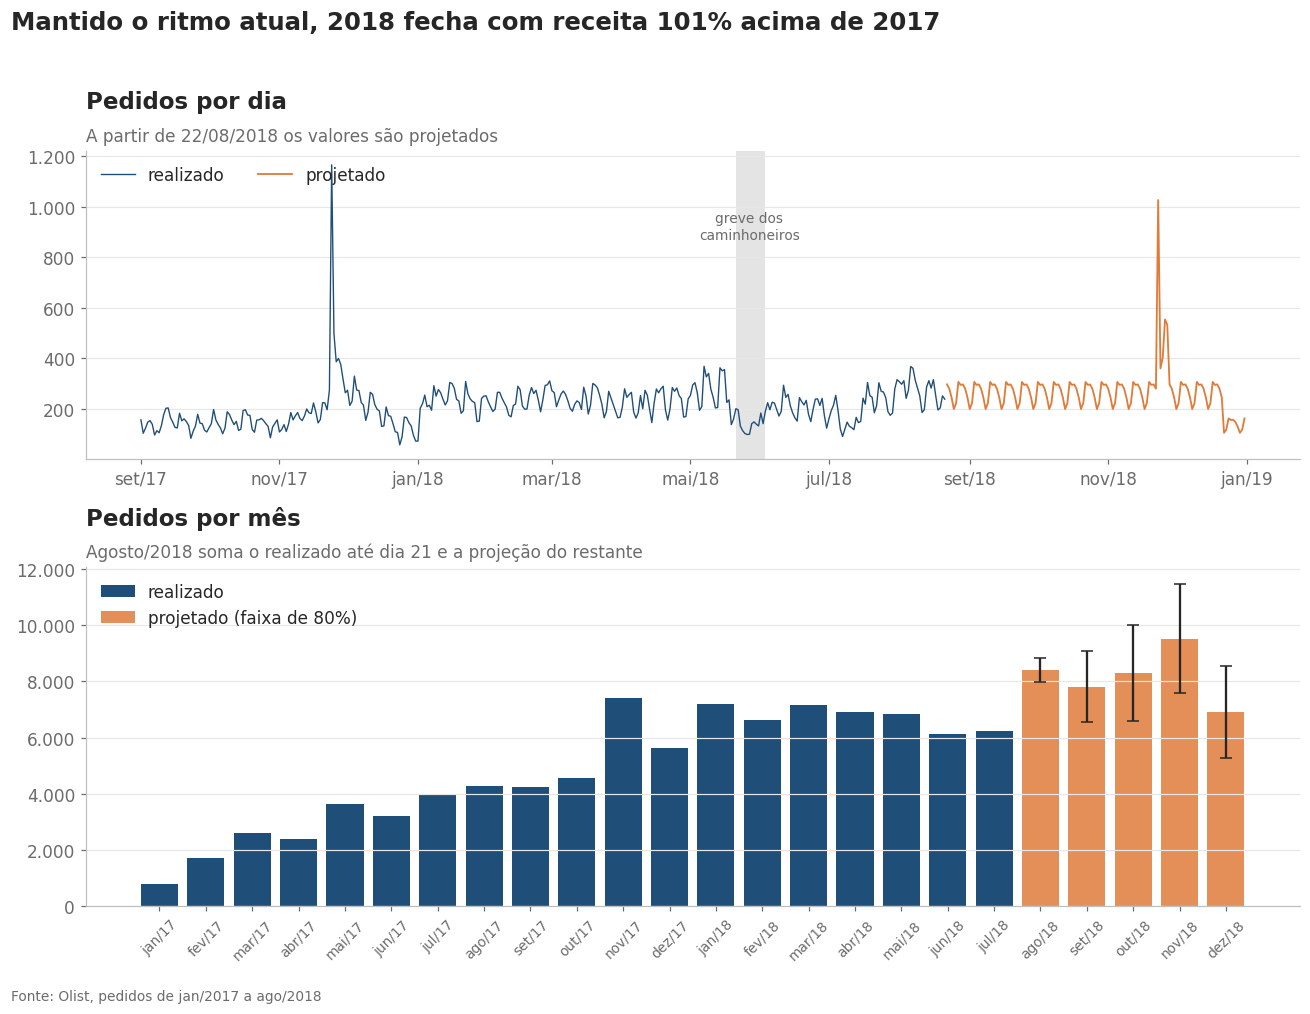

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={"height_ratios": [1, 1.1]})
ax = axes[0]
historico = serie.loc["2017-09-01":]
ax.plot(historico.index, historico.values, color=CORES["principal"], lw=0.9, label="realizado")
ax.plot(diario_previsto.index, diario_previsto.values, color=CORES["destaque"], lw=1.2, label="projetado")
ax.axvspan(pd.Timestamp("2018-05-21"), pd.Timestamp("2018-06-03"), color=CORES["neutro"], alpha=0.3, lw=0)
ax.text(pd.Timestamp("2018-05-27"), historico.max() * 0.75, "greve dos\ncaminhoneiros", ha="center", fontsize=9, color=CORES["subtexto"])
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.xaxis.set_major_formatter(viz.eixo_mes)
ax.legend(loc="upper left", ncol=2)
viz.titulo(ax, "Pedidos por dia", "A partir de 22/08/2018 os valores são projetados")

ax = axes[1]
meses_real = [viz.mes_ano(m) for m in mensal_real.index]
ax.bar(meses_real, mensal_real.pedidos, color=CORES["principal"], label="realizado")
ax.bar(projecao.index, projecao.central, color=CORES["destaque"], alpha=0.85,
       yerr=[projecao.central - projecao.p10, projecao.p90 - projecao.central], capsize=4, ecolor=CORES["texto"], label="projetado (faixa de 80%)")
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.legend(loc="upper left")
viz.titulo(ax, "Pedidos por mês", "Agosto/2018 soma o realizado até dia 21 e a projeção do restante")
fig.suptitle(f"Mantido o ritmo atual, 2018 fecha com receita {pct(crescimento_2018, 0)} acima de 2017",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
viz.fonte(fig)
viz.salvar(fig, "06_previsao")

## 4. Como ler esta projeção

- A projeção supõe que **nada muda**: o mesmo ritmo de vendas de agosto/2018, a mesma operação e o mesmo ticket médio. As recomendações do notebook 07 são justamente alavancas para superar esse cenário.
- O efeito da **Black Friday** foi estimado com um único evento anterior (2017). O tamanho do pico de novembro é a parte mais incerta.
- Choques como a greve de 2018 não são previsíveis. A validação mostra que meses afetados por eventos externos ficam fora da faixa de erro típica.
- O dataset público pode não representar 100% do volume da empresa. Os números absolutos valem para a base analisada; as **taxas de crescimento** são a leitura mais robusta.